# Water Loss Analytics
## 03 — Analisis SQL dan EDA
**Raden Satrio Hibatull Rasendriyo**

Setelah cleaning, saya menggunakan 3.507 laporan tahun kalender 2016–2024 untuk analisis awal. Tujuan saya adalah memahami cakupan laporan, membandingkan kehilangan air secara lebih adil, dan menentukan temuan yang layak dibawa ke dashboard serta PPT.

Pertanyaan analisis:
1. Seberapa konsisten cakupan sistem dari tahun ke tahun?
2. Bagaimana tren NRW pada kelompok sistem yang sama?
3. Pada tahun terbaru dalam cakupan, sistem mana yang memiliki volume kehilangan fisik terbesar dan bagaimana konteks ukuran serta kualitas datanya?
4. Bagaimana hasil berubah ketika status, skor validitas, dan penanda data dipertimbangkan?

SQL dijalankan melalui **SQLite lokal** dari Python. File query disimpan agar proses analisis dapat ditelusuri. Notebook ini belum menjalankan BigQuery; jika tugas mensyaratkan platform Google, query perlu dijalankan kembali dan hasilnya diverifikasi di BigQuery sebelum pengumpulan.


### Cara menjalankan
Simpan notebook ini di `water_loss_analytics/notebooks/`. Jalankan notebook 02 terlebih dahulu untuk menghasilkan `data/processed/water_loss_analysis.csv`, kemudian pilih kernel yang sama dan klik **Run All**.

Paket yang diperlukan: pandas, numpy, matplotlib, dan IPython. SQLite tersedia melalui pustaka bawaan Python. Jika paket belum tersedia, gunakan `%pip install pandas numpy matplotlib ipython` pada kernel notebook lalu restart kernel.

Hasil otomatis disimpan ke `sql/`, `outputs/tables/`, dan `outputs/figures/`. File hasil dengan nama yang sama diperbarui saat dijalankan ulang. Database SQL hanya dibuat di memori.


In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

cwd = Path.cwd().resolve()
candidates = []
for base in [cwd, *cwd.parents]:
    candidates.extend([base, base / 'water_loss_analytics', base / '02_Projects/water_loss_analytics'])
ROOT = next((p for p in candidates if (p / 'data/processed/water_loss_analysis.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Jalankan notebook 02 dahulu. File water_loss_analysis.csv belum ditemukan di data/processed.')
df = pd.read_csv(ROOT / 'data/processed/water_loss_analysis.csv',
                 dtype={'organization_id':'string', 'system_id':'string', 'system_key':'string'},
                 encoding='utf-8-sig')
required = ['source_row','system_key','analysis_year','supplier_name','audit_status',
            'water_supplied_af','real_losses_af','apparent_losses_af','non_revenue_water_af',
            'service_connections','validity_score','flag_numeric_adjustment',
            'flag_nonstandard_system_id','flag_noninteger_connections']
if not set(required).issubset(df.columns):
    raise ValueError('Kolom belum sesuai. Gunakan hasil notebook 02 yang terakhir.')
if df.empty:
    raise ValueError('Tabel analisis kosong. Periksa hasil cleaning.')
assert df[['system_key','analysis_year']].notna().all().all()
assert not df.duplicated(['system_key','analysis_year']).any(), 'Ada lebih dari satu laporan per sistem-tahun.'
nums = ['water_supplied_af','real_losses_af','apparent_losses_af',
        'non_revenue_water_af','service_connections','validity_score']
assert np.isfinite(df[nums].to_numpy(dtype=float)).all()
assert df['water_supplied_af'].gt(0).all() and df['service_connections'].gt(0).all()
for col in ['flag_numeric_adjustment','flag_nonstandard_system_id','flag_noninteger_connections']:
    values = df[col].astype('string').str.lower().map({'true':1,'false':0,'1':1,'0':0})
    if values.isna().any():
        raise ValueError(f'Nilai flag tidak dikenal: {col}')
    df[col] = values.astype(int)
years = sorted(df['analysis_year'].astype(int).unique().tolist())
latest_year = int(max(years))
for folder in ['sql','outputs/tables','outputs/figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
conn = sqlite3.connect(':memory:')
df.to_sql('water_loss', conn, index=False, if_exists='replace')
results = {}

def run_query(name, sql, params=None):
    (ROOT / 'sql' / f'{name}.sql').write_text(sql.strip() + '\n', encoding='utf-8')
    table = pd.read_sql_query(sql, conn, params=params)
    table.to_csv(ROOT / 'outputs/tables' / f'{name}.csv', index=False, encoding='utf-8-sig')
    results[name] = table
    return table

plt.rcParams.update({'figure.dpi':120, 'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False})
def save_figure(name):
    plt.tight_layout()
    plt.savefig(ROOT / 'outputs/figures' / f'{name}.png', dpi=180, bbox_inches='tight')
    plt.show()
    plt.close()

print(f'{len(df):,} laporan | {df.system_key.nunique():,} ID gabungan sistem | {years[0]}–{latest_year}')


3,507 laporan | 487 ID gabungan sistem | 2016–2024


### 1. Cakupan data dan komposisi status
Saya menghitung jumlah laporan dan sistem per tahun sebelum membahas tren. Persentase NRW agregat dihitung dari **total NRW / total pasokan × 100**, bukan rata-rata sederhana persentase setiap sistem.

Status `Requirements Addressed` dan `Preliminarily Approved` dapat memiliki komposisi tahun yang berbeda. Perbandingan keduanya tidak boleh langsung dianggap menunjukkan pengaruh status terhadap kehilangan air.


,analysis_year,audit_count,system_count,supplied_af,nrw_af,nrw_pct,real_losses_af
0,2016,367,367,3293634.338,296495.793,9.002,202418.009
1,2017,393,393,3369059.310,325982.073,9.676,224327.584
2,2018,403,403,3336002.655,288079.236,8.635,188362.375
3,2019,401,401,3256779.710,284667.485,8.741,186680.670
4,2020,414,414,3479807.733,319458.548,9.180,217816.168
5,2021,413,413,3355029.228,267233.718,7.965,176473.517
6,2022,390,390,3186989.948,262671.746,8.242,180604.312
7,2023,395,395,2880661.330,244854.261,8.500,165752.141
8,2024,331,331,2329741.238,211434.558,9.075,145352.962


,analysis_year,audit_status,audit_count,nrw_pct,mean_validity_score
0,2016,Preliminarily Approved,43,8.678,60.930
1,2016,Requirements Addressed,324,9.012,59.775
2,2017,Preliminarily Approved,48,10.405,58.458
3,2017,Requirements Addressed,345,9.590,61.794
4,2018,Preliminarily Approved,64,7.699,60.469
5,2018,Requirements Addressed,339,8.814,62.776
6,2019,Preliminarily Approved,63,7.428,61.794
7,2019,Requirements Addressed,338,8.963,63.609
8,2020,Preliminarily Approved,87,9.294,61.943
9,2020,Requirements Addressed,327,9.147,64.761


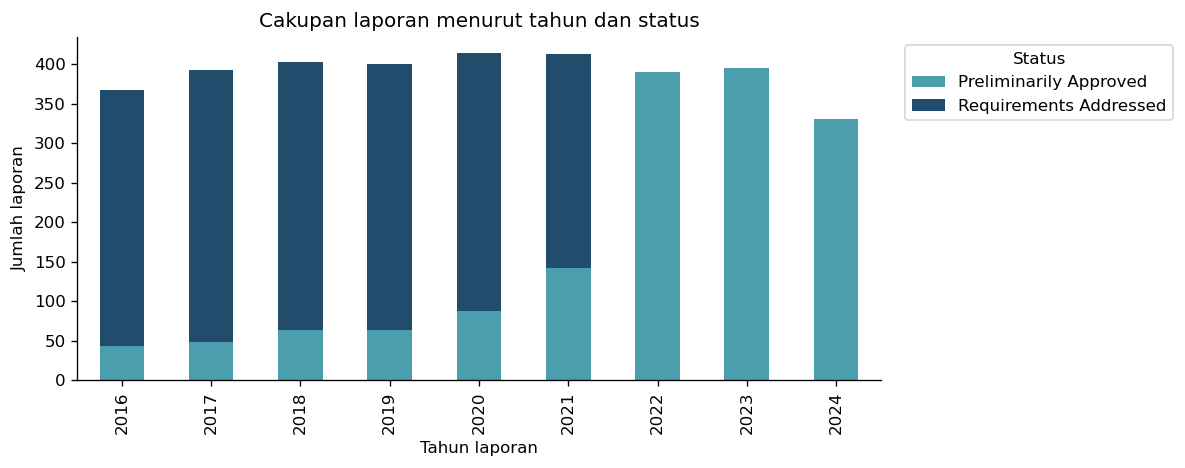

In [2]:
annual = run_query('03_01_annual_coverage', """
SELECT analysis_year, COUNT(*) AS audit_count,
       COUNT(DISTINCT system_key) AS system_count,
       SUM(water_supplied_af) AS supplied_af,
       SUM(non_revenue_water_af) AS nrw_af,
       100.0 * SUM(non_revenue_water_af) / NULLIF(SUM(water_supplied_af),0) AS nrw_pct,
       SUM(real_losses_af) AS real_losses_af
FROM water_loss
GROUP BY analysis_year ORDER BY analysis_year;
""")
status = run_query('03_02_status_by_year', """
SELECT analysis_year, audit_status, COUNT(*) AS audit_count,
       100.0 * SUM(non_revenue_water_af) / NULLIF(SUM(water_supplied_af),0) AS nrw_pct,
       AVG(validity_score) AS mean_validity_score
FROM water_loss
GROUP BY analysis_year, audit_status
ORDER BY analysis_year, audit_status;
""")
display(annual.round(3))
display(status.round(3))
status_counts = status.pivot(index='analysis_year', columns='audit_status', values='audit_count').fillna(0)
status_counts.plot(kind='bar', stacked=True, figsize=(10,4), color=['#4C9DAD','#224C6B'])
plt.ylabel('Jumlah laporan'); plt.xlabel('Tahun laporan')
plt.title('Cakupan laporan menurut tahun dan status')
plt.legend(title='Status', bbox_to_anchor=(1.02,1), loc='upper left')
save_figure('03_01_status_coverage')


### 2. Tren pada kelompok sistem yang sama
Saya membentuk panel seimbang: ID gabungan organisasi–sistem yang memiliki tepat satu laporan pada setiap tahun dalam cakupan. Ini mengurangi perubahan komposisi pelapor, tetapi tidak menjamin wilayah layanan atau metode pengukuran setiap sistem tetap sama.

Panel ini juga dapat lebih mewakili sistem yang konsisten melapor. Hasilnya hanya menggambarkan sampel terpilih, bukan total California. ID yang berubah antarperiode belum digabungkan secara manual.


,analysis_year,system_count,supplied_af,nrw_af,real_losses_af,nrw_pct
0,2016,205,1557476.243,142209.084,94988.349,9.131
1,2017,205,1664839.154,160453.691,105962.290,9.638
2,2018,205,1699491.757,140679.334,88938.050,8.278
3,2019,205,1611182.552,138646.358,89737.865,8.605
4,2020,205,1732157.857,157334.734,103012.499,9.083
5,2021,205,1695384.789,128127.992,79946.566,7.557
6,2022,205,1614029.928,132929.483,89433.204,8.236
7,2023,205,1501158.691,127774.970,85033.885,8.512
8,2024,205,1584307.918,141931.049,96253.938,8.959


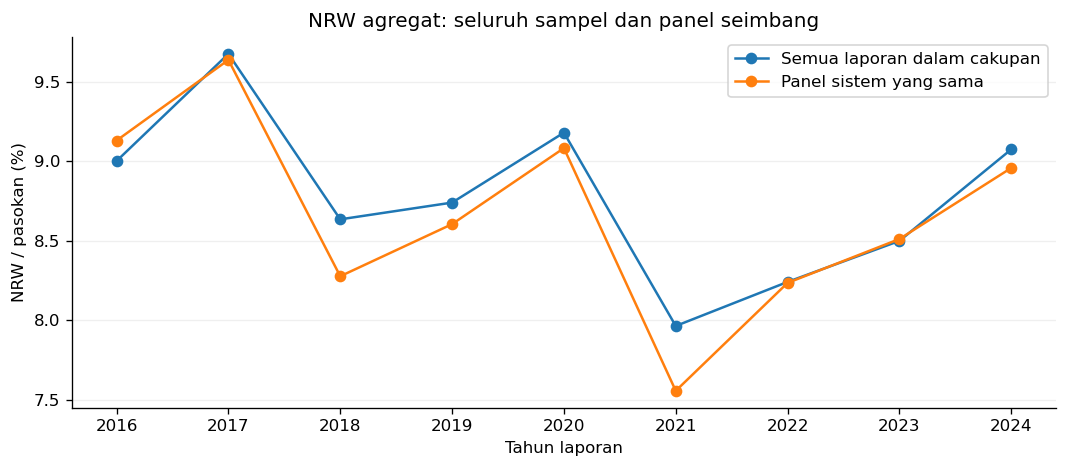

In [3]:
balanced = run_query('03_03_balanced_panel_trend', """
WITH eligible_systems AS (
    SELECT system_key
    FROM water_loss
    GROUP BY system_key
    HAVING COUNT(DISTINCT analysis_year) = (SELECT COUNT(DISTINCT analysis_year) FROM water_loss)
       AND COUNT(*) = (SELECT COUNT(DISTINCT analysis_year) FROM water_loss)
)
SELECT w.analysis_year, COUNT(*) AS system_count,
       SUM(w.water_supplied_af) AS supplied_af,
       SUM(w.non_revenue_water_af) AS nrw_af,
       SUM(w.real_losses_af) AS real_losses_af,
       100.0 * SUM(w.non_revenue_water_af) / NULLIF(SUM(w.water_supplied_af),0) AS nrw_pct
FROM water_loss w JOIN eligible_systems b ON w.system_key = b.system_key
GROUP BY w.analysis_year ORDER BY w.analysis_year;
""")
if balanced.empty:
    print('Tidak ada sistem yang tersedia di seluruh tahun. Tren panel belum dapat dibuat.')
else:
    assert balanced['system_count'].nunique() == 1
    display(balanced.round(3))
    fig, ax = plt.subplots(figsize=(9,4))
    ax.plot(annual['analysis_year'], annual['nrw_pct'], marker='o', label='Semua laporan dalam cakupan')
    ax.plot(balanced['analysis_year'], balanced['nrw_pct'], marker='o', label='Panel sistem yang sama')
    ax.set(xlabel='Tahun laporan', ylabel='NRW / pasokan (%)', title='NRW agregat: seluruh sampel dan panel seimbang')
    ax.set_xticks(years); ax.legend(); ax.grid(axis='y', alpha=.2)
    save_figure('03_02_nrw_trend')


### 3. Volume kehilangan fisik pada tahun terbaru
Saya menampilkan sepuluh laporan dengan volume kehilangan fisik terbesar pada tahun terbaru dalam cakupan. Besarnya volume dapat dipengaruhi ukuran sistem. Karena itu, tabel juga menyertakan rasio terhadap pasokan, jumlah sambungan, skor validitas, dan status.

Daftar ini merupakan titik awal peninjauan, bukan daftar sistem terburuk. Persentase kehilangan dan rasio per sambungan juga tidak cukup untuk menyimpulkan efisiensi teknis tanpa konteks jaringan.


,system_key,supplier_name,analysis_year,audit_status,real_losses_af,water_supplied_af,service_connections,validity_score,real_loss_share_pct,real_loss_af_per_connection_year,flag_nonstandard_system_id,flag_noninteger_connections
0,2175|CA4310011,San Jose Water Company,2024,Preliminarily Approved,5902.820,104180.954,236388.0,74.0,5.666,0.025,0,0
1,2132|CA3410029,Sacramento County Water Agency,2024,Preliminarily Approved,4461.738,29006.581,53520.0,49.0,15.382,0.083,0,0
2,613|CA0710003,Contra Costa Water District,2024,Preliminarily Approved,3302.416,30696.917,62253.0,59.0,10.758,0.053,0,0
3,117|CA1910007,Azusa Light and Water,2024,Preliminarily Approved,3087.268,17195.510,23739.0,72.0,17.954,0.130,0,0
4,2524|CA5010019,Turlock City Of,2024,Preliminarily Approved,2802.707,19966.099,20053.0,48.0,14.037,0.140,0,0
5,2150|CA3610039,San Bernardino City Of,2024,Preliminarily Approved,2781.721,36006.764,47707.0,58.0,7.726,0.058,0,0
6,123|CA1510031,Bakersfield City Of,2024,Preliminarily Approved,2460.159,44280.150,51664.0,63.0,5.556,0.048,0,0
7,727|CA3310005,Desert Water Agency,2024,Preliminarily Approved,2124.962,32758.084,25847.0,73.0,6.487,0.082,0,0
8,816|CA0910001,El Dorado Irrigation District,2024,Preliminarily Approved,2111.770,30547.220,44646.0,73.0,6.913,0.047,0,0
9,2111|CA3110008,Roseville City Of,2024,Preliminarily Approved,2098.729,31160.160,52102.0,74.0,6.735,0.040,0,0


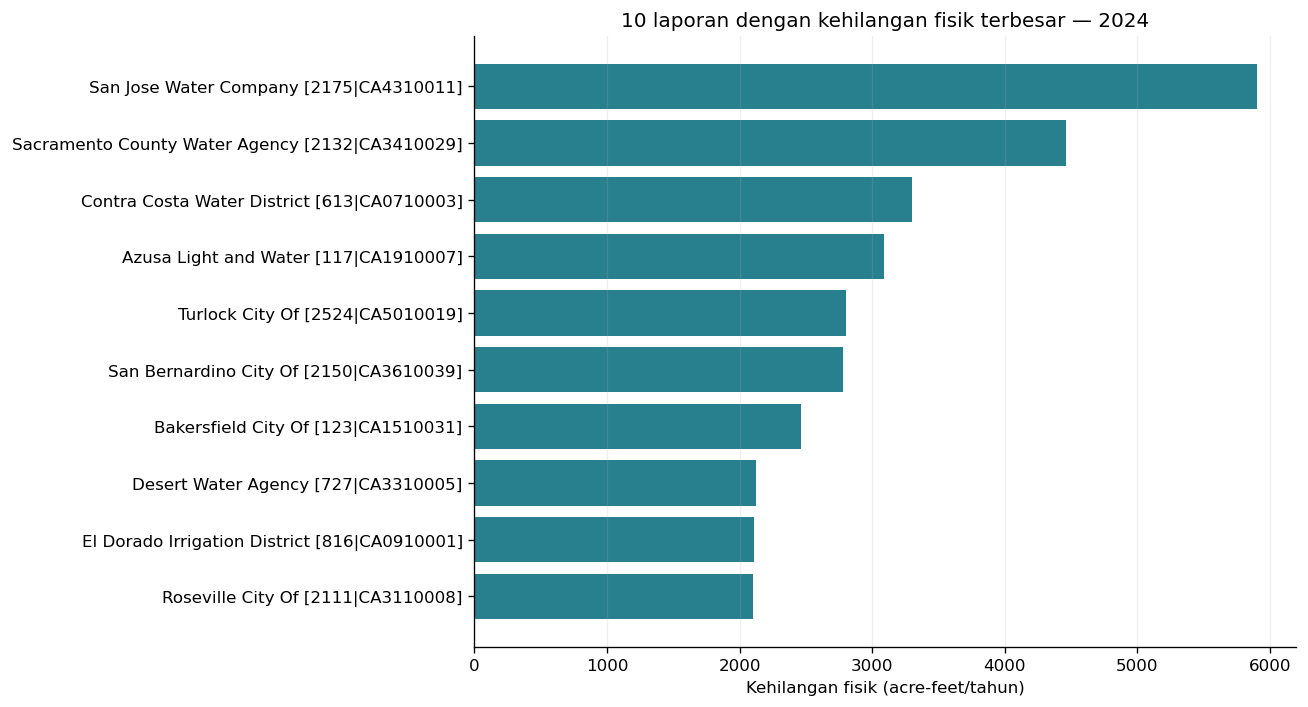

In [4]:
top = run_query('03_04_latest_top_real_losses', """
SELECT system_key, supplier_name, analysis_year, audit_status,
       real_losses_af, water_supplied_af, service_connections, validity_score,
       100.0 * real_losses_af / NULLIF(water_supplied_af,0) AS real_loss_share_pct,
       real_losses_af / NULLIF(service_connections,0) AS real_loss_af_per_connection_year,
       flag_nonstandard_system_id, flag_noninteger_connections
FROM water_loss
WHERE analysis_year = (SELECT MAX(analysis_year) FROM water_loss)
ORDER BY real_losses_af DESC, system_key
LIMIT 10;
""")
display(top.round(3))
plot_top = top.sort_values('real_losses_af')
labels = plot_top['supplier_name'] + ' [' + plot_top['system_key'] + ']'
fig, ax = plt.subplots(figsize=(11,6))
ax.barh(labels, plot_top['real_losses_af'], color='#287F8E')
ax.set(xlabel='Kehilangan fisik (acre-feet/tahun)',
       title=f'10 laporan dengan kehilangan fisik terbesar — {latest_year}')
ax.grid(axis='x', alpha=.2)
save_figure('03_03_top_real_losses')


### 4. Konsentrasi kehilangan fisik
Saya menghitung porsi kehilangan fisik pada sepuluh sistem terbesar di tahun terbaru. Angkanya dihitung langsung dari data; saya tidak mengasumsikan pola 80/20. Konsentrasi volume dapat membantu memilih laporan untuk ditinjau, tetapi tidak membuktikan besarnya penghematan yang dapat dicapai.


In [5]:
concentration = run_query('03_05_loss_concentration', """
WITH ranked AS (
  SELECT system_key, real_losses_af,
         ROW_NUMBER() OVER (ORDER BY real_losses_af DESC, system_key) AS loss_rank
  FROM water_loss
  WHERE analysis_year = (SELECT MAX(analysis_year) FROM water_loss)
)
SELECT COUNT(*) AS system_count, SUM(real_losses_af) AS total_real_losses_af,
       SUM(CASE WHEN loss_rank <= 10 THEN real_losses_af ELSE 0 END) AS top10_real_losses_af,
       100.0 * SUM(CASE WHEN loss_rank <= 10 THEN real_losses_af ELSE 0 END)
       / NULLIF(SUM(real_losses_af),0) AS top10_share_pct
FROM ranked;
""")
display(concentration.round(3))


,system_count,total_real_losses_af,top10_real_losses_af,top10_share_pct
0,331,145352.962,31134.289,21.42


### 5. Sensitivitas hasil terhadap pilihan data
Saya membandingkan hasil dalam tahun yang sama agar perbedaan periode tidak tercampur dengan perbedaan status. Kelompok di bawah saling tumpang tindih dan **tidak boleh dijumlahkan**.

Skor ≥70 hanya merupakan skenario sensitivitas proyek, bukan ambang resmi kelayakan data. Saya juga memeriksa hasil setelah mengeluarkan laporan dengan penyesuaian numerik atau format ID yang berbeda. Jumlah sambungan pecahan dipertahankan pada analisis utama, lalu diuji melalui skenario tersendiri.

Kelompok yang tidak tersedia pada tahun tertentu ditampilkan sebagai kosong. Tidak ada estimasi NRW untuk kelompok kosong.


scenario,01 Semua cakupan utama,02 Requirements Addressed saja,03 Skor validitas >= 70 (eksploratif),04 Tanpa penyesuaian numerik,05 Format ID CA dan 7 digit,06 Jumlah sambungan bulat
analysis_year,,,,,,
2016,9.002,9.012,6.342,9.002,9.002,9.002
2017,9.676,9.590,8.835,9.676,9.676,9.676
2018,8.635,8.814,7.654,8.635,8.635,8.635
2019,8.741,8.963,7.306,8.741,8.741,8.909
2020,9.180,9.147,8.223,9.180,9.180,9.346
2021,7.965,8.759,6.848,7.965,7.961,8.051
2022,8.242,NaN,8.260,8.242,8.242,8.390
2023,8.500,NaN,8.268,8.500,8.500,8.678
2024,9.075,NaN,8.065,9.075,9.075,9.317


Jumlah laporan per skenario (kelompok kosong ditampilkan 0):


scenario,01 Semua cakupan utama,02 Requirements Addressed saja,03 Skor validitas >= 70 (eksploratif),04 Tanpa penyesuaian numerik,05 Format ID CA dan 7 digit,06 Jumlah sambungan bulat
analysis_year,,,,,,
2016,367,324,50,367,367,367
2017,393,345,71,392,393,393
2018,403,339,85,402,403,403
2019,401,338,109,400,401,389
2020,414,327,130,414,412,379
2021,413,271,125,413,411,349
2022,390,0,118,390,390,356
2023,395,0,170,395,395,352
2024,331,0,131,331,331,310


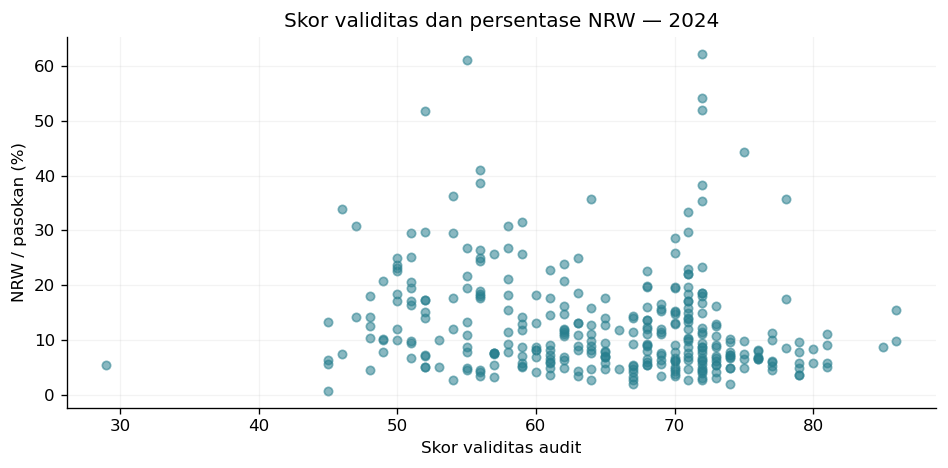

Grafik ini bersifat deskriptif; pola sebaran tidak membuktikan sebab-akibat.


In [6]:
sensitivity = run_query('03_06_sensitivity_by_year', """
WITH scenarios AS (
 SELECT *, '01 Semua cakupan utama' AS scenario FROM water_loss
 UNION ALL
 SELECT *, '02 Requirements Addressed saja' FROM water_loss
 WHERE audit_status = 'Requirements Addressed'
 UNION ALL
 SELECT *, '03 Skor validitas >= 70 (eksploratif)' FROM water_loss WHERE validity_score >= 70
 UNION ALL
 SELECT *, '04 Tanpa penyesuaian numerik' FROM water_loss WHERE flag_numeric_adjustment = 0
 UNION ALL
 SELECT *, '05 Format ID CA dan 7 digit' FROM water_loss WHERE flag_nonstandard_system_id = 0
 UNION ALL
 SELECT *, '06 Jumlah sambungan bulat' FROM water_loss WHERE flag_noninteger_connections = 0
)
SELECT analysis_year, scenario, COUNT(*) AS audit_count,
       SUM(water_supplied_af) AS supplied_af,
       100.0 * SUM(non_revenue_water_af) / NULLIF(SUM(water_supplied_af),0) AS nrw_pct
FROM scenarios
GROUP BY analysis_year, scenario ORDER BY analysis_year, scenario;
""")
display(sensitivity.pivot(index='analysis_year', columns='scenario', values='nrw_pct').round(3))
print('Jumlah laporan per skenario (kelompok kosong ditampilkan 0):')
display(sensitivity.pivot(index='analysis_year', columns='scenario', values='audit_count').fillna(0).astype(int))

latest = df.loc[df['analysis_year'].eq(latest_year)].copy()
latest['nrw_pct'] = 100 * latest['non_revenue_water_af'] / latest['water_supplied_af']
fig, ax = plt.subplots(figsize=(8,4))
ax.scatter(latest['validity_score'], latest['nrw_pct'], color='#287F8E', alpha=.55, s=25)
ax.set(xlabel='Skor validitas audit', ylabel='NRW / pasokan (%)',
       title=f'Skor validitas dan persentase NRW — {latest_year}')
ax.grid(alpha=.15)
save_figure('03_04_validity_vs_nrw')
print('Grafik ini bersifat deskriptif; pola sebaran tidak membuktikan sebab-akibat.')


### 6. Ringkasan angka untuk dibahas
Sel berikut menghasilkan ringkasan dari tabel SQL yang sudah diperiksa. Angka ini masih perlu dibaca bersama cakupan data. Ringkasan disimpan agar angka untuk PPT dan dashboard dapat ditelusuri.


In [7]:
# Verifikasi independen: hasil agregasi SQL harus sama dengan perhitungan pandas.
check = df.groupby('analysis_year').agg(nrw=('non_revenue_water_af','sum'),
                                      supply=('water_supplied_af','sum'))
expected = (100 * check['nrw'] / check['supply']).reindex(annual['analysis_year']).to_numpy()
assert np.allclose(expected, annual['nrw_pct'].to_numpy())
assert int(annual['audit_count'].sum()) == len(df)
assert np.isclose(top['real_losses_af'].sum(), concentration.loc[0,'top10_real_losses_af'])

last = annual.loc[annual['analysis_year'].eq(latest_year)].iloc[0]
lines = [
    '# Ringkasan awal SQL dan EDA',
    f'- Cakupan analisis: {len(df):,} laporan pada {years[0]}–{latest_year}.',
    f'- Tahun {latest_year}: {int(last.audit_count)} laporan; NRW agregat {last.nrw_pct:.2f}%.',
    f'- Sepuluh laporan terbesar menyumbang {concentration.loc[0, "top10_share_pct"]:.2f}% kehilangan fisik dalam sampel tahun {latest_year}.',
]
if not balanced.empty:
    first_b, last_b = balanced.iloc[0], balanced.iloc[-1]
    delta_pp = last_b.nrw_pct - first_b.nrw_pct
    lines += [f'- Panel seimbang: {int(first_b.system_count)} ID gabungan sistem setiap tahun.',
              f'- NRW panel: {first_b.nrw_pct:.2f}% menjadi {last_b.nrw_pct:.2f}%; perubahan {delta_pp:+.2f} poin persentase.']
addressed_years = set(status.loc[status['audit_status'].eq('Requirements Addressed'),'analysis_year'])
absent = [str(y) for y in years if y not in addressed_years]
if absent:
    lines.append('- Requirements Addressed tidak tersedia dalam sampel pada: ' + ', '.join(absent) + '.')
lines += ['', 'Batas interpretasi:',
          '- Hasil berlaku untuk sampel yang lolos aturan proyek; bukan total seluruh California.',
          '- Panel memakai ID gabungan yang sama; perubahan cakupan layanan dan ID belum diverifikasi secara eksternal.',
          '- Konsentrasi kehilangan bukan estimasi penghematan atau bukti buruknya pengelolaan.',
          '- Perbedaan status dan skor validitas perlu dibaca bersama komposisi sistem serta tahun.',
          '', 'Tindak lanjut:',
          '- Tinjau laporan dengan volume besar bersama ukuran sistem, skor audit, dan riwayat tahunnya.',
          '- Gunakan tren panel untuk pembahasan perubahan waktu, dengan tetap menampilkan cakupan sampel.',
          '- Sajikan definisi metrik dan filter cakupan secara jelas dalam dashboard.']
summary = '\n'.join(lines)
(ROOT / 'outputs/tables/03_insight_notes.md').write_text(summary, encoding='utf-8')
print(summary)
conn.close()
print('Selesai: 6 query SQL, 6 tabel CSV, ringkasan Markdown, dan grafik tersimpan.')


# Ringkasan awal SQL dan EDA
- Cakupan analisis: 3,507 laporan pada 2016–2024.
- Tahun 2024: 331 laporan; NRW agregat 9.08%.
- Sepuluh laporan terbesar menyumbang 21.42% kehilangan fisik dalam sampel tahun 2024.
- Panel seimbang: 205 ID gabungan sistem setiap tahun.
- NRW panel: 9.13% menjadi 8.96%; perubahan -0.17 poin persentase.
- Requirements Addressed tidak tersedia dalam sampel pada: 2022, 2023, 2024.

Batas interpretasi:
- Hasil berlaku untuk sampel yang lolos aturan proyek; bukan total seluruh California.
- Panel memakai ID gabungan yang sama; perubahan cakupan layanan dan ID belum diverifikasi secara eksternal.
- Konsentrasi kehilangan bukan estimasi penghematan atau bukti buruknya pengelolaan.
- Perbedaan status dan skor validitas perlu dibaca bersama komposisi sistem serta tahun.

Tindak lanjut:
- Tinjau laporan dengan volume besar bersama ukuran sistem, skor audit, dan riwayat tahunnya.
- Gunakan tren panel untuk pembahasan perubahan waktu, dengan tetap menampilkan cakupan 

### Langkah berikutnya
Saya perlu meninjau ringkasan dan grafik sebelum memilih insight utama. Setelah hasilnya konsisten, tahap berikutnya adalah menyusun dashboard Streamlit yang memuat cakupan data, tren panel, profil sistem, dan catatan kualitas. PPT menggunakan angka dari tabel yang sama agar hasilnya konsisten.
